# F1-04 — Phân tích khám phá thời gian vòng đua

Phân tích **39.433 vòng train 2022–2023** thuộc 43 phiên đua theo chặng sau khi áp dụng
[giao thức F1-03](experiment-protocol.md). Trong 42.098 dòng train trước lọc, 2.665 dòng nằm
ngoài phạm vi. Có 19.324 vòng năm 2022 và 20.109 vòng năm 2023 được phân tích.
[Metadata](../reports/eda/metadata.json) lưu phiên bản nguồn, SHA-256 của dữ liệu, config,
mã chạy và các đầu ra. Tệp Parquet nguồn được đọc theo năm trong cấu hình.


Các bảng và biểu đồ đã được lưu trong notebook. Có hai cách tạo lại kết quả.

- **Trong VS Code**, bấm **Select Kernel** → **Python Environments...**, chọn Python 3.11
  trong `.venv` của dự án (`.venv\Scripts\python.exe` trên Windows). Nếu VS Code yêu cầu
  cài `ipykernel`, bấm **Install**. Sau đó bấm **Run All** để tạo và hiển thị kết quả mới.
  Lưu notebook để lần sau mở lại thấy kết quả vừa chạy.
- **Từ terminal**, chạy lệnh sau tại thư mục gốc repo để tạo lại bảng và hình trong
  `reports/eda/`.

  ```sh
  uv run --locked python -m scripts.run_eda
  ```

In [1]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd()
repo = next(
    (path for path in (cwd, *cwd.parents) if (path / "scripts" / "run_eda.py").is_file()),
    None,
)
if repo is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục dự án f1-laptime-regression.")

run = subprocess.run(
    [sys.executable, "-m", "scripts.run_eda"],
    cwd=repo,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    check=False,
)
print(run.stdout.strip())
run.check_returncode()
report = repo / "reports" / "eda"
figures = report / "figures"

Train rows analyzed: 39,433
EDA outputs: reports/eda/


## Phân phối và các vòng ở đuôi phân phối

Trung vị `LapTimeSec` là **87,305 giây**. Một nửa số vòng nằm trong khoảng
**79,835–98,109 giây** (Q1–Q3). Phân vị 1% và 99% lần lượt là 69,852 và 118,767 giây.
Để phát hiện vòng khác thường trong bối cảnh của nó, tính hai ngưỡng
`Q1 − 1,5 × IQR` và `Q3 + 1,5 × IQR` riêng theo mùa, chặng và phiên.
Quy tắc đánh dấu 115 vòng dưới ngưỡng và 466 vòng trên ngưỡng. Mọi vòng đó vẫn nằm trong
phân tích. Để quyết định loại vòng, nhóm cần bằng chứng cụ thể về lỗi dữ liệu hoặc quy tắc
phạm vi phù hợp với bài toán.

,Số vòng,Q1 (giây),Trung vị (giây),Q3 (giây)
Phạm vi,,,,
Toàn bộ train,39433,79.835,87.305,98.109
2022,19324,81.240,87.828,97.998
2023,20109,79.246,86.893,98.147


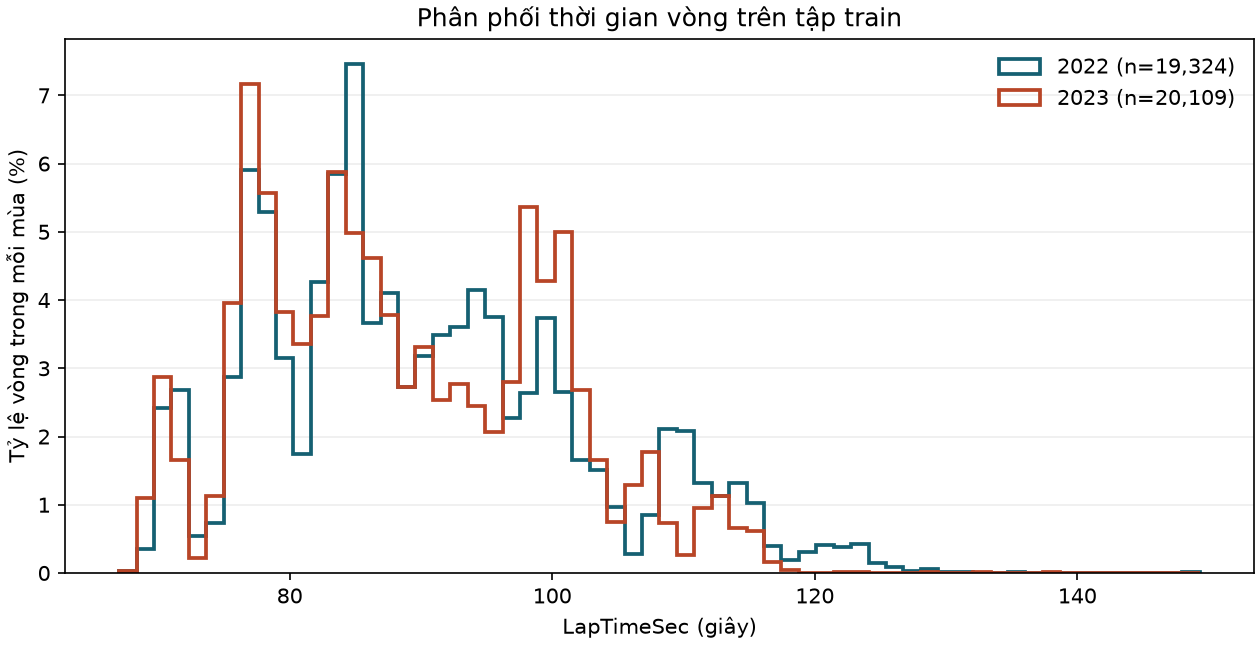

In [2]:
target_table = pd.read_csv(report / "target-summary.csv")
target_table["Phạm vi"] = (
    target_table["Year"].astype("Int64").astype("string").fillna("Toàn bộ train")
)
target_columns = {
    "n": "Số vòng",
    "q1_s": "Q1 (giây)",
    "median_s": "Trung vị (giây)",
    "q3_s": "Q3 (giây)",
}
display(
    target_table[["Phạm vi", *target_columns]]
    .rename(columns=target_columns)
    .round(3)
    .set_index("Phạm vi")
)
display(Image(filename=str(figures / "target-distribution.png"), width=800))

## Khác biệt theo chặng và mùa

Trung vị trải từ **70,475 giây** ở Austrian GP 2023 (1.178 vòng) đến **119,484 giây**
ở Singapore GP 2022 (625 vòng). Độ phân tán cũng khác nhau. IQR ở Austrian GP 2023 là
1,305 giây, còn Monaco GP 2022 là 16,814 giây. Có 24 tên chặng trong train, trong đó 19
xuất hiện ở cả hai mùa. Với 19 chặng chung, trung vị năm 2023 thấp hơn năm 2022 ở cả 19,
với mức chênh điển hình là **1,025 giây** tính bằng trung vị của 19 chênh lệch. Thành phần
tay đua, lốp và điều kiện thi đấu có thể khác giữa hai mùa.

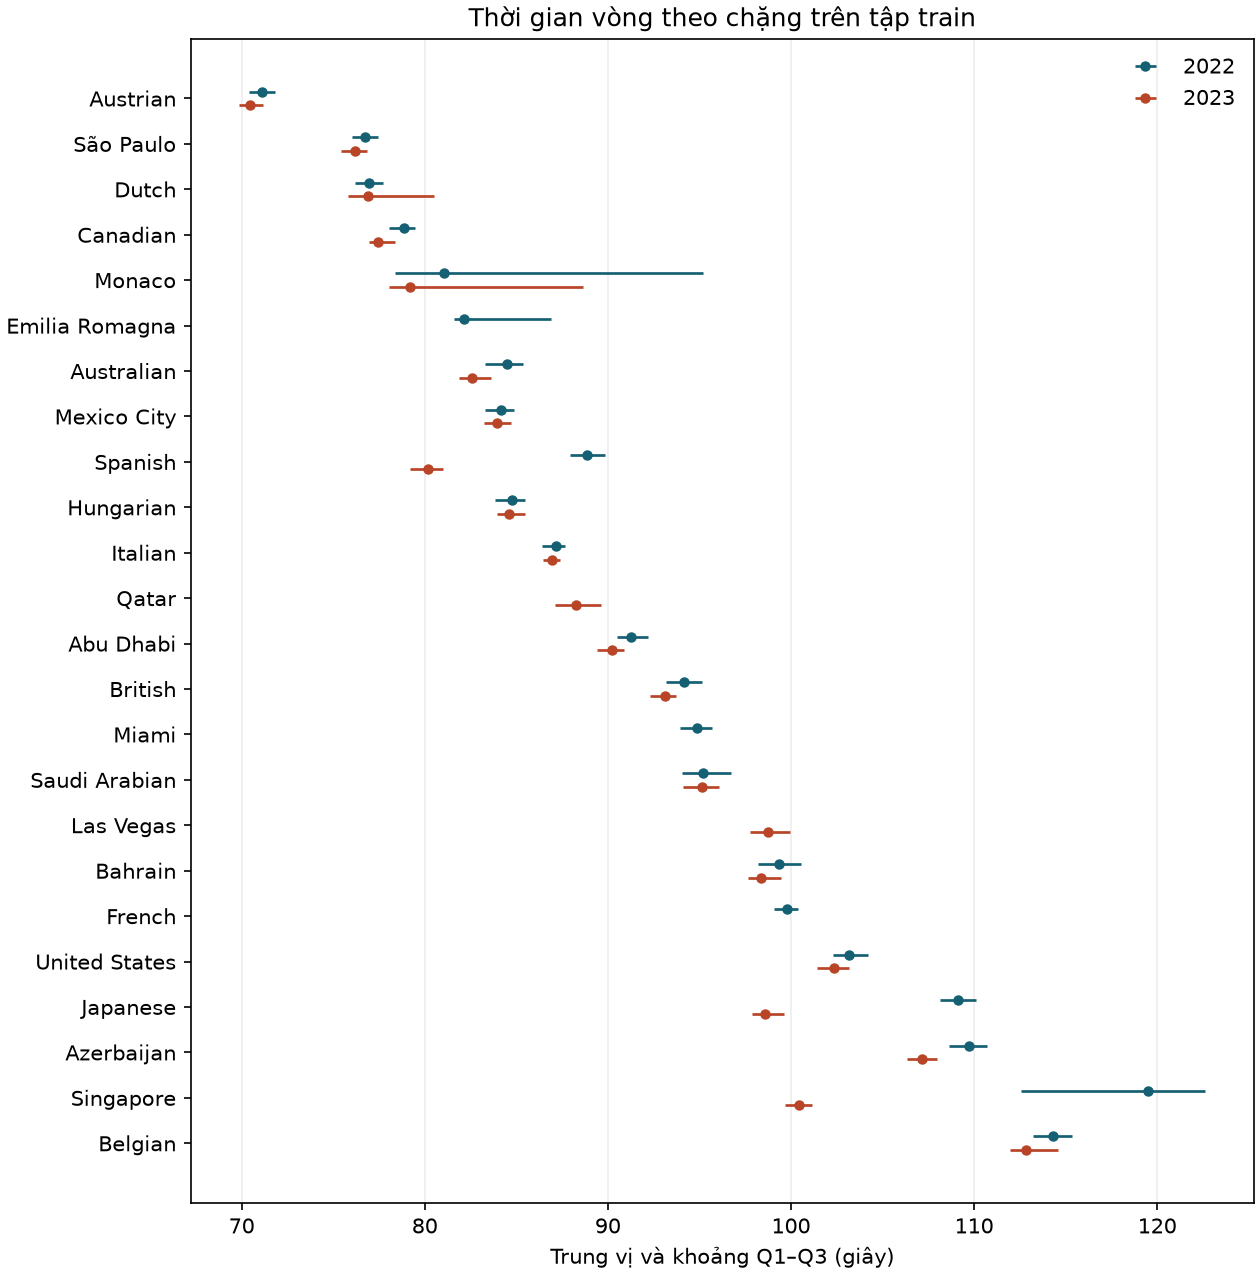

In [3]:
display(Image(filename=str(figures / "event-lap-times.png"), width=720))

## Quan hệ giữa đặc trưng và thời gian vòng

Tính số liệu riêng theo phiên đua trong từng chặng. Mỗi phép so sánh dùng ít nhất 30 vòng
ở mỗi nhóm liên quan, và tương quan Pearson cần biến thiên ở cả hai biến. Mỗi chặng đủ mẫu
đóng góp một giá trị cho thống kê trung vị của phép so sánh đó.

| Đặc trưng | Kết quả quan sát trên train |
|---|---|
| `LapNumber` | Tương quan Pearson với lap time âm ở **42/43** phiên, trung vị **r = −0,519**. |
| `Compound` | So với trung vị của `MEDIUM` trong cùng phiên, chênh lệch trung vị điển hình là **−0,336 giây** cho `HARD` (37 phiên) và **−0,443 giây** cho `SOFT` (20 phiên). Dấu chênh lệch thay đổi giữa các phiên. `INTERMEDIATE` và `WET` chỉ có lần lượt 5 và 2 phiên đủ mẫu để so với `MEDIUM`. |
| `TyreLife_start` | Sau khi tách theo phiên và loại lốp, tương quan với lap time có cả dấu âm và dương. Trung vị r là **−0,057** cho `HARD` (38 nhóm), **−0,108** cho `MEDIUM` (41 nhóm) và **−0,131** cho `SOFT` (21 nhóm). |

Các so sánh theo lốp giữ chặng và mùa cố định. Vị trí trong cuộc đua, tay đua và điều kiện
thi đấu vẫn có thể khác giữa các nhóm. Vì vậy, chênh lệch mô tả ở đây chưa xác định tác
động riêng của loại lốp hoặc tuổi lốp.

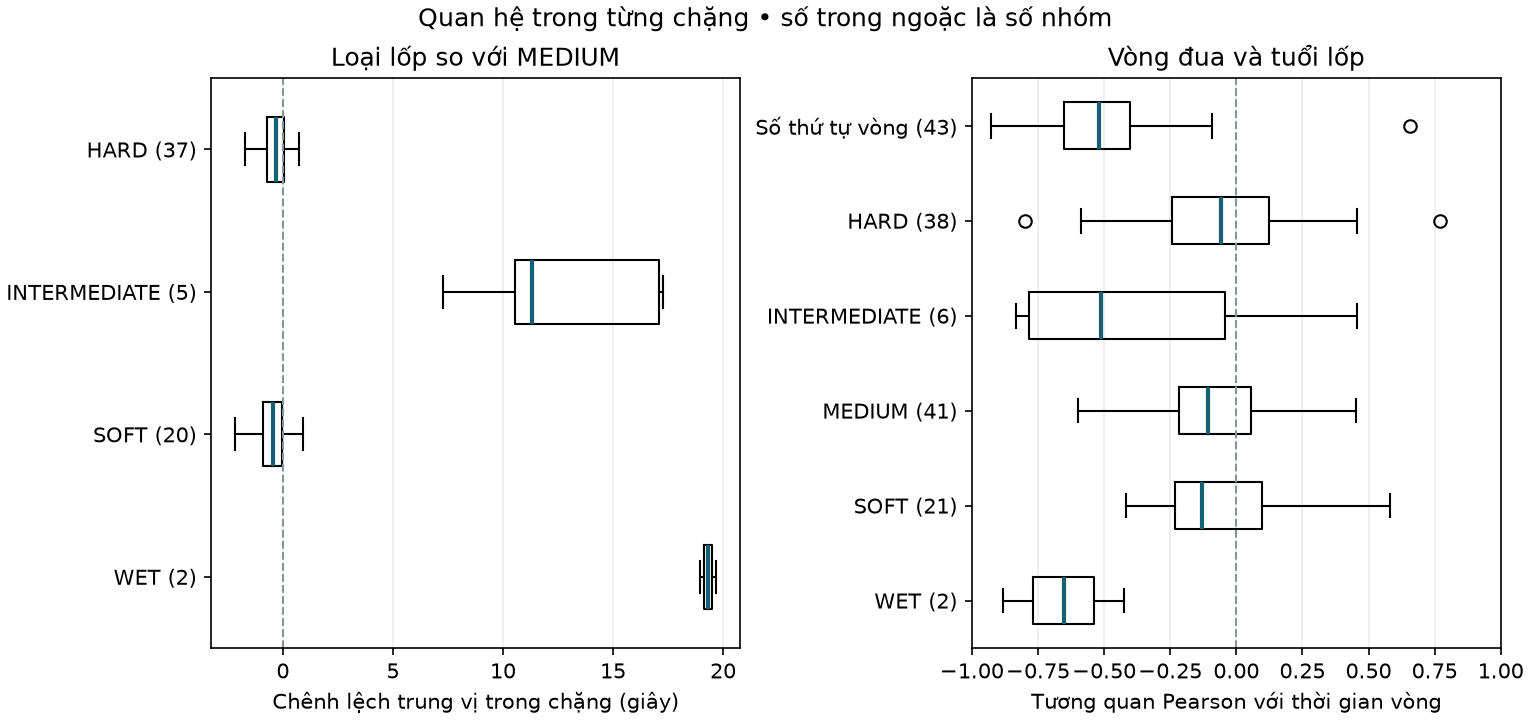

In [4]:
display(Image(filename=str(figures / "feature-relationships.png"), width=960))

## Giá trị thiếu

- **F1-05** chuẩn hóa chuỗi giả thiếu của `Compound` theo config. Trên train, `Compound`
  thiếu **327 vòng** sau khi quy về giá trị thiếu và `TyreLife` thiếu **428 vòng**. Mỗi biến
  chỉ thiếu ở ba phiên đua. Riêng Austrian GP 2022 có 259 vòng thiếu `Compound` và 307 vòng
  thiếu `TyreLife` trên 1.176 vòng. Nên đối chiếu số đếm này khi kiểm tra dữ liệu bàn giao.

Ở Austrian GP 2022, lap time trung vị là **70,411 giây** ở 307 vòng thiếu `TyreLife` và
**71,485 giây** ở 869 vòng có dữ liệu tuổi lốp. Cả hai nhóm đều được tính trong thống kê
phân phối `LapTimeSec` và chênh lệch giữa hai trung vị là **1,074 giây**.

Tương quan Pearson với `TyreLife_start` được tính riêng theo loại lốp trong phiên đua.
Mỗi vòng dùng để tính phải có cả tuổi lốp và `Compound`. Mỗi nhóm cần ít nhất 30 vòng,
và cả `TyreLife_start` lẫn `LapTimeSec` đều phải có biến thiên. Tại chặng này, **842 trong
869 vòng** có tuổi lốp được dùng để tính tương quan, gồm **544 vòng HARD** và **298 vòng
MEDIUM**. Trong 869 vòng có tuổi lốp, **27 vòng** thiếu `Compound` nên không được dùng để
tính tương quan theo loại lốp.
Chênh lệch trung vị mô tả hai nhóm trong mẫu quan sát. Ảnh hưởng của cách xử lý
giá trị thiếu lên sai số dự đoán cần được đo ở F1-06.

In [5]:
group_table = pd.read_csv(report / "group-summary.csv")
event_table = group_table.loc[group_table["group"].eq("event")]
missing_columns = ["missing_compound_n", "missing_tyre_life_n"]
has_missing = event_table[missing_columns].gt(0).any(axis=1)
missing_table = event_table.loc[has_missing, ["Year", "EventName", "n", *missing_columns]]
display(
    missing_table.rename(
        columns={
            "Year": "Mùa",
            "EventName": "Chặng",
            "n": "Số vòng",
            "missing_compound_n": "Thiếu Compound",
            "missing_tyre_life_n": "Thiếu TyreLife",
        }
    ).set_index(["Mùa", "Chặng"])
)

Số vòng  Thiếu Compound  Thiếu TyreLife
Mùa  Chặng                                                       
2022 Austrian Grand Prix     1176             259             307
     Monaco Grand Prix        949              33              86
2023 Canadian Grand Prix     1127              35              35

## Đề xuất cho bước mô hình

- **F1-06** có thể dùng `EventName` làm mốc so sánh, rồi kiểm tra mức cải thiện khi thêm
  `LapNumber`. So sánh tiếp thiết kế có `Compound` và `TyreLife_start` bằng MAE trên
  validation 2024 theo protocol. Nên xem thêm sai số theo chặng để thấy nơi mô hình dự đoán
  kém, nhất là khi gặp chặng chưa xuất hiện trong train.
- **Giữ bộ lọc hiện tại.** Dùng các cờ IQR để xem lại những phiên có đuôi
  dài, ví dụ Emilia Romagna GP 2022 có 64 vòng trên ngưỡng. EDA hiện kiểm tra các quan hệ
  mô tả. Mức cải thiện dự đoán của từng đặc trưng cần được đo ở F1-06.